# Explore willingness to pay and arrival timing

Run this notebook inside the workspace created by Notebook 01, before Notebook 03.

We inspect two distributions: how much a potential customer is willing to pay, and when potential customers arrive. A sale occurs only when a customer arrives, accepts the offered price, and a room is available. Each accepted sale permanently consumes one room.

The values are invented assumptions, not observations. Distinguish probability density from probability mass and daily arrival probability as you read the plots.

In [1]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display
import yaml

with open('config.yaml', encoding='utf-8') as file:
    config = yaml.safe_load(file)
assert config.get('workflow') == 'pricing-workshop-v1', 'Generate a fresh workspace with Notebook 01 first.'

def load_model(name):
    with open(f'model/{name}.pickle', 'rb') as file:
        return pickle.load(file)

mu, sigma = load_model('wtp_parameters')
price_min, price_max, price_step = load_model('opt_table_params')
visit = load_model('visit_curve')
days = np.arange(config['leadtime'] + 1)
figure_dir = Path('fig/distributions')
figure_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

def save_chart(fig, name):
    fig.tight_layout()
    fig.savefig(figure_dir / name, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(pd.DataFrame([
    ('Scenario', config['scenario']),
    ('Room capacity', config['capacity']),
    ('Maximum days before check-in', config['leadtime']),
    ('Expected potential arrivals at multiplier 1', config['expected_total_arrivals']),
    ('WTP mean / standard deviation', f'{mu:g} / {sigma:g}'),
], columns=['Parameter', 'Value']))

,Parameter,Value
0,Scenario,pricing_demo
1,Room capacity,10
2,Maximum days before check-in,60
3,Expected potential arrivals at multiplier 1,18
4,WTP mean / standard deviation,18000 / 6000


## 1. Willingness to pay: density and purchase probability

Willingness to pay (WTP) follows the configured normal distribution. The **area** under the density over a price interval is a probability; the curve height itself is not.

At offered price $p$, the purchase probability is $\Pr(\mathrm{WTP} \geq p)$. The right-hand plot shows this tail probability on the available price grid. Capacity and arrivals also matter before a purchase becomes an accepted booking.

The normal model permits negative WTP. We show that tail explicitly; the simulator does not truncate it. At positive prices, such customers do not buy. Currency units are arbitrary.

**Discuss:** If the mean WTP rises while the offered price stays fixed, what happens to purchase probability?

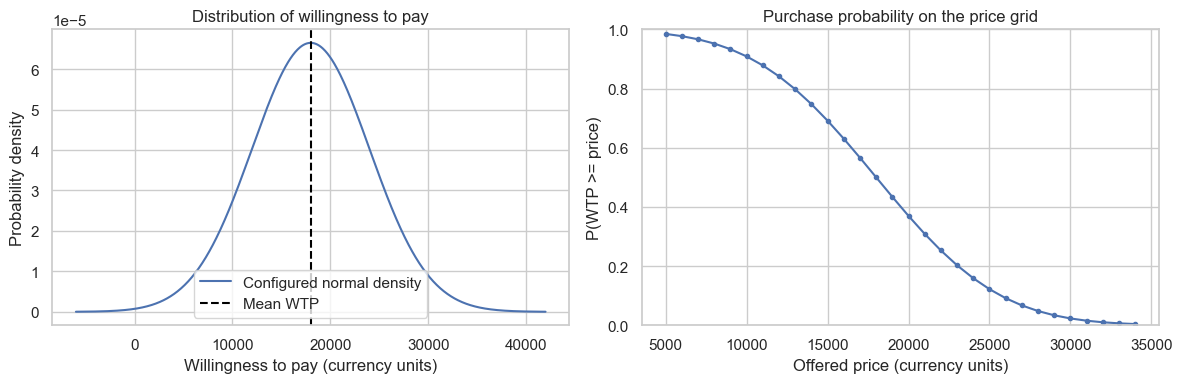

Probability of negative WTP: 0.1350%
Purchase probability at the mean WTP: 50.0%


In [2]:
x = np.linspace(min(mu - 4 * sigma, price_min), max(mu + 4 * sigma, price_max), 800)
prices = np.arange(price_min, price_max, price_step)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, norm.pdf(x, mu, sigma), label='Configured normal density')
axes[0].axvline(mu, color='black', linestyle='--', label='Mean WTP')
axes[0].set(xlabel='Willingness to pay (currency units)', ylabel='Probability density', title='Distribution of willingness to pay')
axes[0].legend()
axes[1].plot(prices, norm.sf(prices, mu, sigma), marker='o', markersize=3)
axes[1].set(xlabel='Offered price (currency units)', ylabel='P(WTP >= price)', ylim=(0, 1), title='Purchase probability on the price grid')
save_chart(fig, '01_willingness_to_pay.png')
print(f'Probability of negative WTP: {norm.cdf(0, mu, sigma):.4%}')
print(f'Purchase probability at the mean WTP: {norm.sf(mu, mu, sigma):.1%}')

## 2. Arrivals: timing weights versus daily arrival probabilities

The left-hand plot shows **discrete probability mass** for potential-customer arrival timing: a lognormal distribution integrated over each daily interval and normalised within the booking horizon. These weights sum to one.

The right-hand plot multiplies each weight by `arrival.expected_total_arrivals` and a demand multiplier. The resulting value is the probability of one potential customer arriving that day. The simulator allows **at most one arrival per day**, so every value must be between zero and one. The sum across days is the expected number of potential arrivals, not the number of accepted bookings.

**Read the horizontal axis carefully:** larger values mean earlier relative to check-in. The simulation proceeds from the largest lead time down to zero.

**Discuss:** Increasing `arrival.expected_total_arrivals` changes the height of the daily arrival probabilities, but does it change the timing weights?

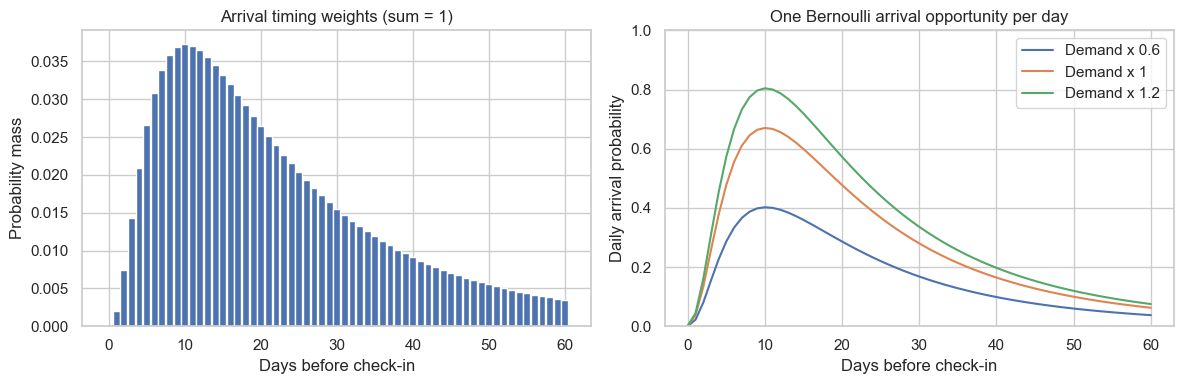

,Demand multiplier,Expected potential arrivals,Maximum daily probability
0,0.6,10.8,0.402193
1,1.0,18.0,0.670321
2,1.2,21.6,0.804385


In [3]:
weights = visit.loc[days, 'visit'].to_numpy()
arrival_probabilities = {
    multiplier: weights * config['expected_total_arrivals'] * multiplier
    for multiplier in config['lambda_multiplier']
}
assert np.isclose(weights.sum(), 1)
assert all(np.all((p >= 0) & (p <= 1)) for p in arrival_probabilities.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(days, weights, width=0.9)
axes[0].set(xlabel='Days before check-in', ylabel='Probability mass', title='Arrival timing weights (sum = 1)')
for multiplier, probabilities in arrival_probabilities.items():
    axes[1].plot(days, probabilities, label=f'Demand x {multiplier:g}')
axes[1].set(xlabel='Days before check-in', ylabel='Daily arrival probability', ylim=(0, 1), title='One Bernoulli arrival opportunity per day')
axes[1].legend()
save_chart(fig, '02_arrival_probabilities.png')
display(pd.DataFrame([
    {'Demand multiplier': m, 'Expected potential arrivals': p.sum(), 'Maximum daily probability': p.max()}
    for m, p in arrival_probabilities.items()
]))

## Predict before calculating

1. For a fixed offered price, what happens to purchase probability if mean WTP rises?
2. If potential arrivals increase, would you charge more or less when only two rooms remain?
3. How might the answer change when ten rooms remain?

Continue with Notebook 03 to test these predictions. The two figures are saved in `fig/distributions/`. To try different input distributions, edit the scenario used by Notebook 01 and create a new workspace.